# EO Spatial Split Planner

Measured directional image dependence, buffered train/validation/test partitions, and a matched random split comparison on a native Sentinel-2 reflectance raster. This prototype implements the [concept note](https://docs.google.com/document/d/12IIlu0eEh_bVcY3pnii98iE5CrnEY80DatgcOOmFLEM/edit).


In [1]:
from pathlib import Path
import json
import sys

from IPython.display import Image, JSON, display

_here = Path.cwd()
REPO_ROOT = next(
    p for p in [_here, _here / "agentic-eo", *_here.parents]
    if (p / "lib" / "agentic_eo").is_dir()
)
TOOL_ROOT = REPO_ROOT / "examples" / "eo-spatial-split-planner"
ARTIFACTS = TOOL_ROOT / "artifacts"
sys.path.insert(0, str(TOOL_ROOT))
import server as planner


## Sentinel-2 measurement

The AOI is south of central Berlin. The analysis uses native 20 m B05 surface reflectance and excludes pixels outside SCL classes 4, 5, and 6. The cached report records the exact scene, calibration, pixel spacing, and mask. Set `RECOMPUTE` to refresh the real public STAC acquisition.


In [2]:
RECOMPUTE = False
report_path = ARTIFACTS / "real_demo_report.json"

if RECOMPUTE or not report_path.exists():
    response = planner.plan_sentinel2_split(
        bbox=[13.30, 52.35, 13.50, 52.50],
        start_date="2024-06-01",
        end_date="2024-08-31",
        band="B05",
        max_cloud_cover=10,
        seed=42,
    )
    if response.get("status") != "ok":
        raise RuntimeError(response.get("error", response))
    report_path = Path(response["artifacts"]["report_json"])

report = json.loads(report_path.read_text())
display(JSON(report))


<IPython.core.display.JSON object>

## Dependence and spatial partitions

The diagnostic compares empirical directional dependence with the stripe partition and buffered exclusions. Distances are measured on a projected metre grid. The estimated decorrelation range is a heuristic for the selected image band; a range that is unresolved within the AOI remains flagged.


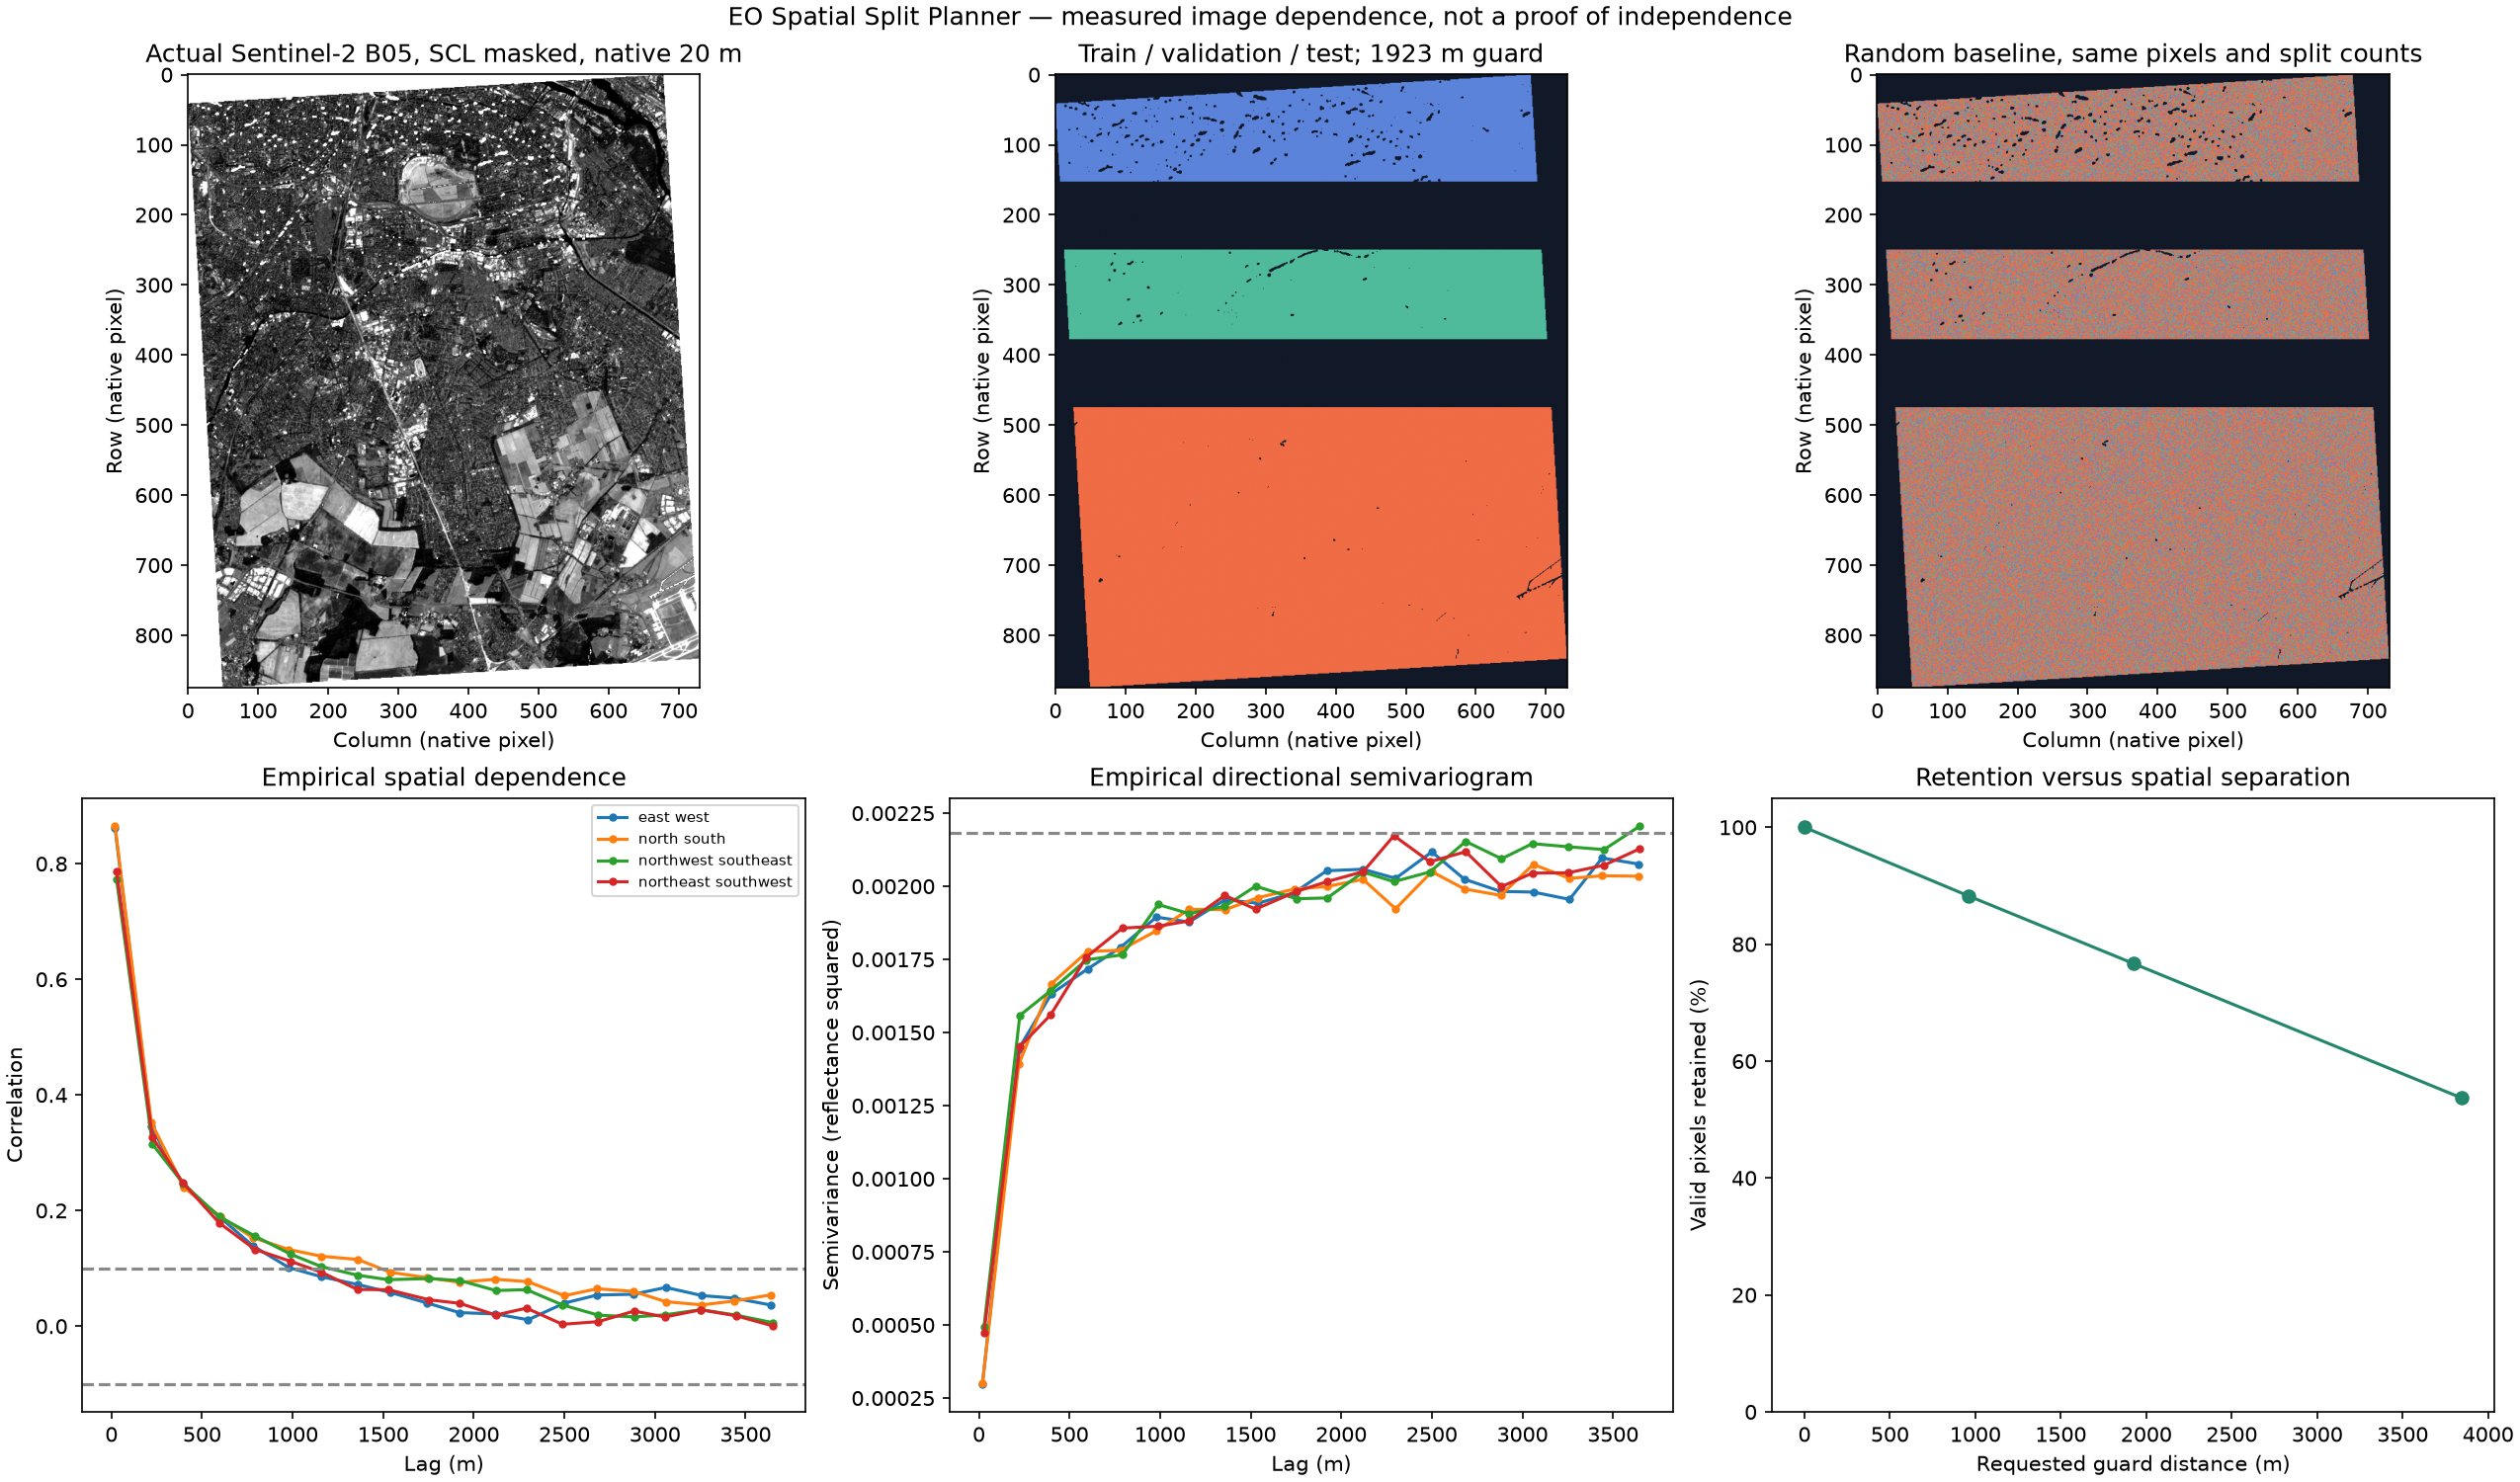

<IPython.core.display.JSON object>

In [3]:
diagnostic = ARTIFACTS / "diagnostic.png"
if diagnostic.exists() and not RECOMPUTE:
    display(Image(filename=str(diagnostic)))
else:
    print("Run the real demo script to produce the diagnostic for this acquisition.")

sensitivity_path = ARTIFACTS / "sensitivity.json"
if sensitivity_path.exists() and not RECOMPUTE:
    display(JSON(json.loads(sensitivity_path.read_text())))


## MCP contract

The two tools accept either a Sentinel-2 search or a local numeric GeoTIFF. Results contain compact diagnostics and paths to a split-mask GeoTIFF, the analysis raster, and full JSON evidence on the server filesystem.


In [4]:
from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters, stdio_client

server_parameters = StdioServerParameters(
    command=sys.executable,
    args=[str(TOOL_ROOT / "server.py"), "--transport", "stdio"],
)
async with stdio_client(server_parameters) as (read, write):
    async with ClientSession(read, write) as session:
        await session.initialize()
        tools = await session.list_tools()
        display(JSON({tool.name: tool.inputSchema for tool in tools.tools}))


<IPython.core.display.JSON object>

## EVE integration evidence

The saved gateway discovery records whether this account exposes an existing Sentinel-2 imagery tool. The optional EVE result records the actual model/tool trace, including hosted geocoding and the local planner. Public STAC imagery acquisition is recorded separately in the scene provenance.

The raw EVE answer below is preserved as generated. Its interpretation needs these corrections:

- Discarded valid pixels are guard-gap exclusions. Cloud/nodata masking precedes the valid-pixel denominator.
- The 1,931.72 m footprint gap is a conservative lower bound; the minimum center distance is exactly 1,960 m.
- The very low scene cloud percentage is catalogue metadata and does not guarantee cloud-free AOI pixels.
- The phrase “prevent leakage” overstates the geometry check: it does not prove independence of labels, other features, or repeated acquisitions.


In [5]:
for filename in ("eve_gateway_discovery.json", "eve_demo.json"):
    evidence_path = ARTIFACTS / filename
    if evidence_path.exists():
        evidence = json.loads(evidence_path.read_text())
        if filename == "eve_demo.json":
            display(JSON({
                key: evidence[key]
                for key in ("tested_at_utc", "model", "servers", "verification", "answer")
                if key in evidence
            }))
        else:
            display(JSON({
                "tested_at_utc": evidence.get("tested_at_utc"),
                "sentinel2_discovery_calls": evidence.get("sentinel2_discovery_calls"),
                "imagery_access_note": evidence.get("imagery_access_note"),
            }))
    else:
        print(f"No saved evidence: {filename}")


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## Interpretation

This analysis checks the geometry and dependence of a single spectral band. Spatial separation can reduce nearby-pixel leakage, but it does not establish label independence, independence across all bands, temporal transferability, or a downstream model's accuracy. The stripe split may change land-cover composition; inspect class balance and choose the intended geographic and temporal evaluation design before training.
